# Clustering Part 1 — K-Means on CC GENERAL

**Review 2 notebook.** Includes dataset audit, EDA, missing-value handling, feature scaling, elbow curve, K-Means cluster assignments, the three required internal metrics, PCA visualization, t-SNE visualization, and cluster profiling.

**Important:** clustering discovers groups; it does not predict a supplied target. Cluster IDs are arbitrary labels.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load dataset

In [2]:
# Locate the uploaded dataset whether this notebook is run from the project root or notebooks/.
candidates = [
    Path("CC_GENERAL.csv"), Path("CC GENERAL.csv"), Path("CC GENERAL(1).csv"), Path("CC GENERAL(2).csv"),
    Path("data/CC_GENERAL.csv"), Path("../data/CC_GENERAL.csv"), Path("data/CC GENERAL.csv"), Path("../data/CC GENERAL.csv"),
    Path("../CC GENERAL.csv"), Path("../CC GENERAL(1).csv")
]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Place CC GENERAL.csv beside this notebook or in a data/ folder.")

df = pd.read_csv(data_path)
print(f"Loaded: {data_path} | Shape: {df.shape}")
display(df.head())

Loaded: ../data/CC_GENERAL.csv | Shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## 2. Dataset audit

In [3]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))
print("Missing values in raw dataset:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Duplicate rows:", df.duplicated().sum())
print("Numeric summary:")
display(df.describe().T)

Data types:


,dtype
CUST_ID,object
BALANCE,float64
BALANCE_FREQUENCY,float64
PURCHASES,float64
ONEOFF_PURCHASES,float64
INSTALLMENTS_PURCHASES,float64
CASH_ADVANCE,float64
PURCHASES_FREQUENCY,float64
ONEOFF_PURCHASES_FREQUENCY,float64
PURCHASES_INSTALLMENTS_FREQUENCY,float64


Missing values in raw dataset:


,missing
MINIMUM_PAYMENTS,313
CREDIT_LIMIT,1
BALANCE,0
CUST_ID,0
BALANCE_FREQUENCY,0
PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0


Duplicate rows: 0
Numeric summary:


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


## 3. EDA — distributions

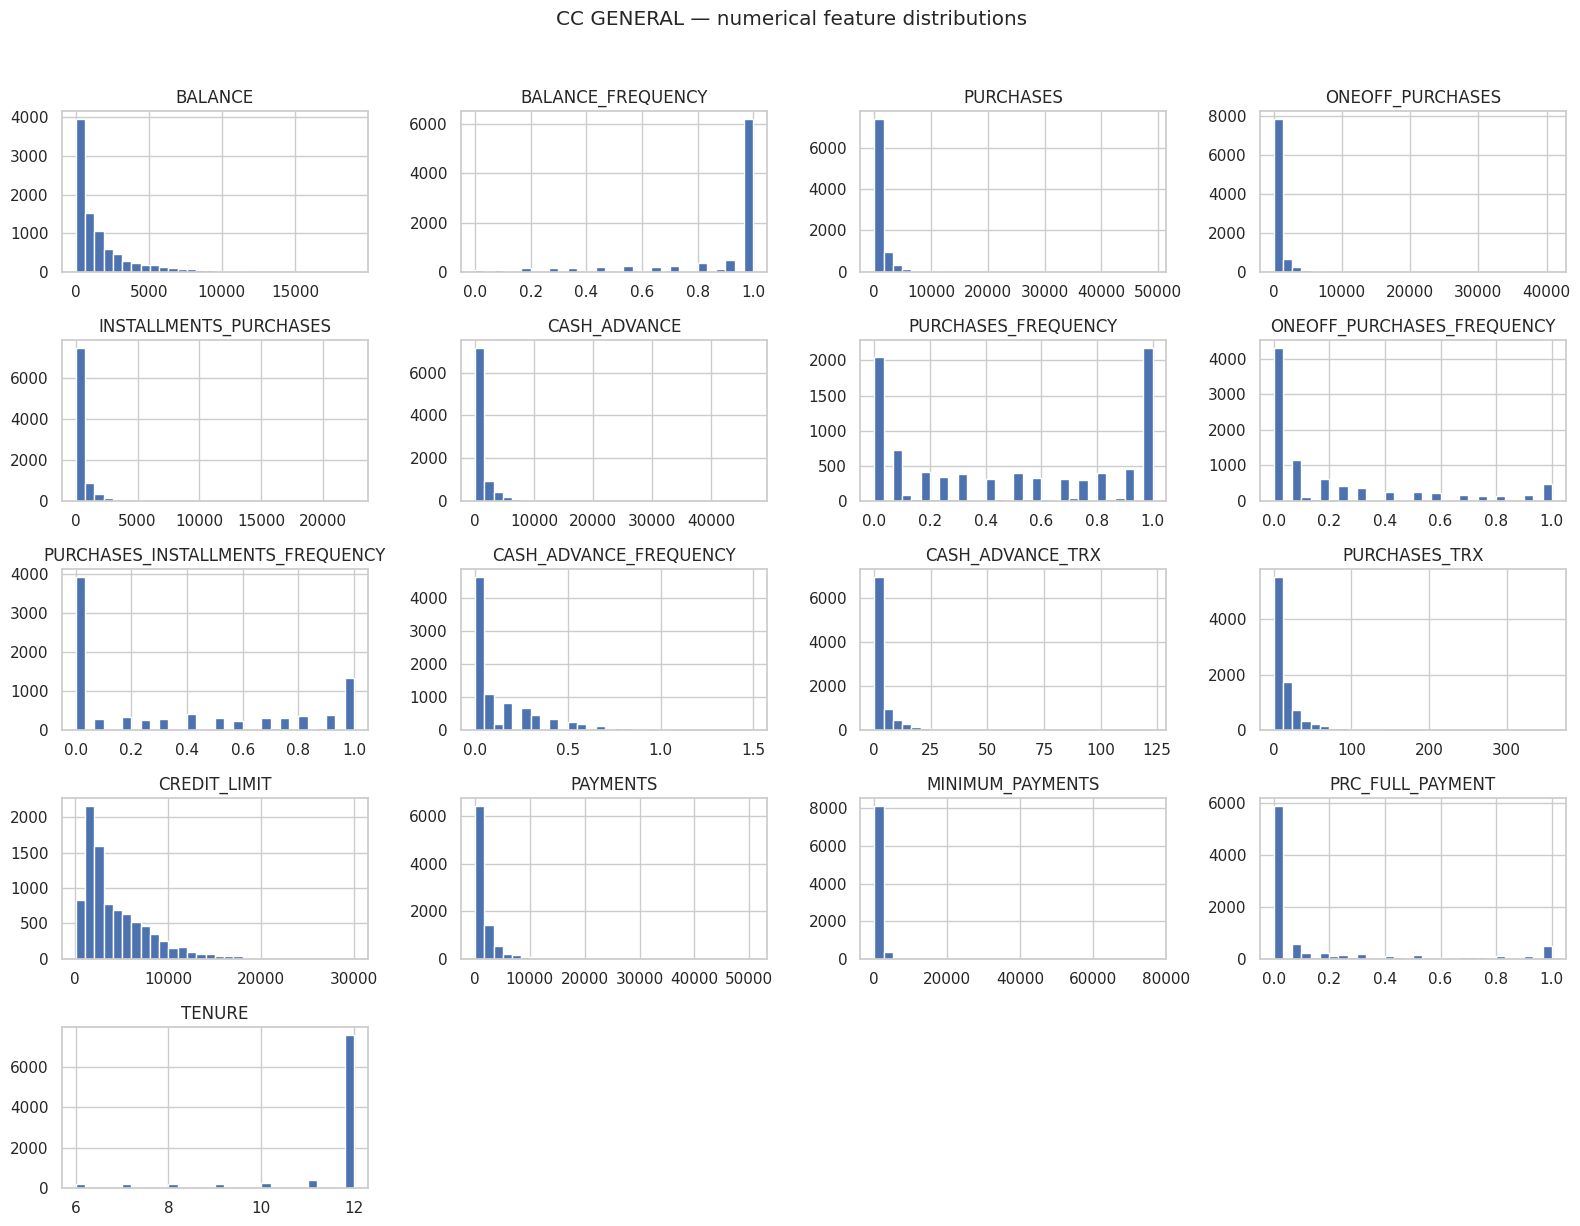

In [4]:
# Raw numeric feature distributions (log-like skew is expected for monetary variables).
raw_numeric = df.select_dtypes(include=np.number).drop(columns=["CUST_ID"], errors="ignore")
raw_numeric.hist(figsize=(16, 12), bins=30, layout=(-1, 4))
plt.suptitle("CC GENERAL — numerical feature distributions", y=1.02)
plt.tight_layout()
plt.show()

## Cleaning and scaling

Missing numeric values are imputed with the median. The identifier is removed, and features are standardized before distance-based clustering. Keep the preprocessing choices and their reasons in the final report.

In [5]:
# CUST_ID is an identifier, not a meaningful distance-based feature.
# There is no target column used to fit clustering models.
work = df.drop(columns=["CUST_ID"], errors="ignore").copy()
work = work.apply(pd.to_numeric, errors="coerce")

print("Missing values before imputation:")
display(work.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Duplicate rows:", work.duplicated().sum())

# Median imputation is robust to skewed spending variables; standardization prevents
# high-magnitude monetary columns from dominating distance calculations.
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(work)
feature_names = work.columns.tolist()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_names)
print("Scaled feature matrix:", X_scaled.shape)

Missing values before imputation:


,missing
MINIMUM_PAYMENTS,313
CREDIT_LIMIT,1
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
PURCHASES_INSTALLMENTS_FREQUENCY,0


Duplicate rows: 0
Scaled feature matrix: (8950, 17)


## 4. Elbow method — select k

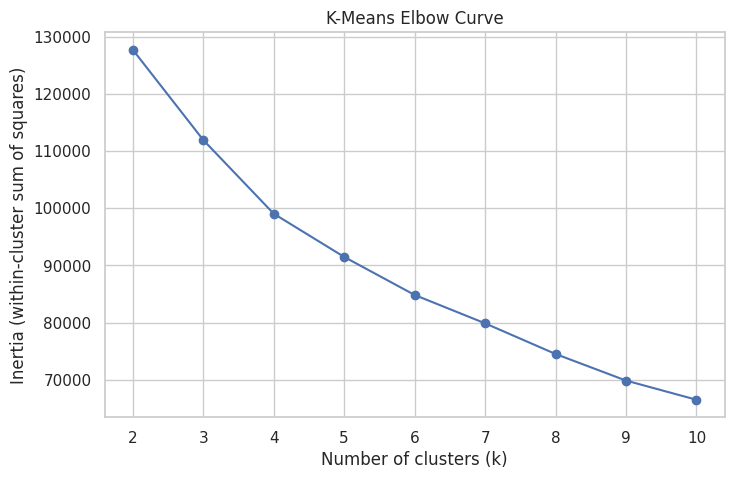

Chosen k: 4 — review the elbow plot and adjust if justified.


In [6]:
inertias = []
k_values = range(2, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.title("K-Means Elbow Curve")
plt.show()

# Inspect the curve and choose a defensible k; 4 is a starting point, not a guaranteed optimum.
K_CHOSEN = 4
print("Chosen k:", K_CHOSEN, "— review the elbow plot and adjust if justified.")

## 5. Fit final K-Means and generate cluster labels

In [7]:
kmeans = KMeans(n_clusters=K_CHOSEN, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
clustered = df.copy()
clustered["Cluster"] = kmeans_labels
print("Cluster counts:")
display(clustered["Cluster"].value_counts().sort_index().rename("customers").to_frame())
display(clustered[["Cluster"]].head())

Cluster counts:


,customers
Cluster,
0,3977
1,409
2,1197
3,3367


,Cluster
0,0
1,2
2,3
3,0
4,0


## 6. Evaluation metrics

In [8]:
# Silhouette is estimated on a reproducible sample to keep runtime reasonable;
# Davies–Bouldin and Calinski–Harabasz are computed on the complete scaled dataset.
metrics = {
    "Silhouette Score (sample up to 3000)": silhouette_score(X_scaled, kmeans_labels, sample_size=min(3000, len(X_scaled)), random_state=RANDOM_STATE),
    "Davies–Bouldin Index": davies_bouldin_score(X_scaled, kmeans_labels),
    "Calinski–Harabasz Index": calinski_harabasz_score(X_scaled, kmeans_labels),
}
display(pd.DataFrame([metrics], index=["K-Means"]).T.rename(columns={"K-Means":"Score"}))
print("Interpretation: higher silhouette and Calinski–Harabasz are generally better; lower Davies–Bouldin is generally better.")

,Score
Silhouette Score (sample up to 3000),0.196547
Davies–Bouldin Index,1.574837
Calinski–Harabasz Index,1598.076876


Interpretation: higher silhouette and Calinski–Harabasz are generally better; lower Davies–Bouldin is generally better.


## 7. PCA — 2D cluster visualization

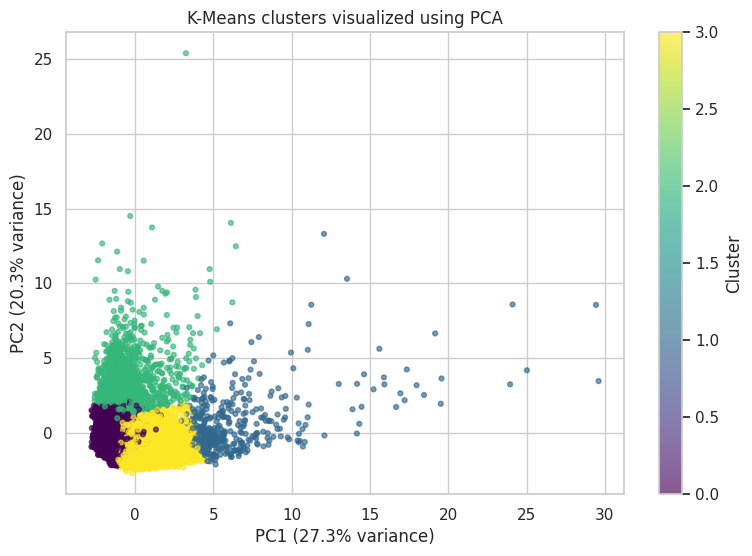

Total variance explained by 2 PCs: 0.4761


In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="viridis", s=12, alpha=0.65)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("K-Means clusters visualized using PCA")
plt.colorbar(scatter, label="Cluster")
plt.show()
print("Total variance explained by 2 PCs:", round(pca.explained_variance_ratio_.sum(), 4))

## 8. t-SNE visualization

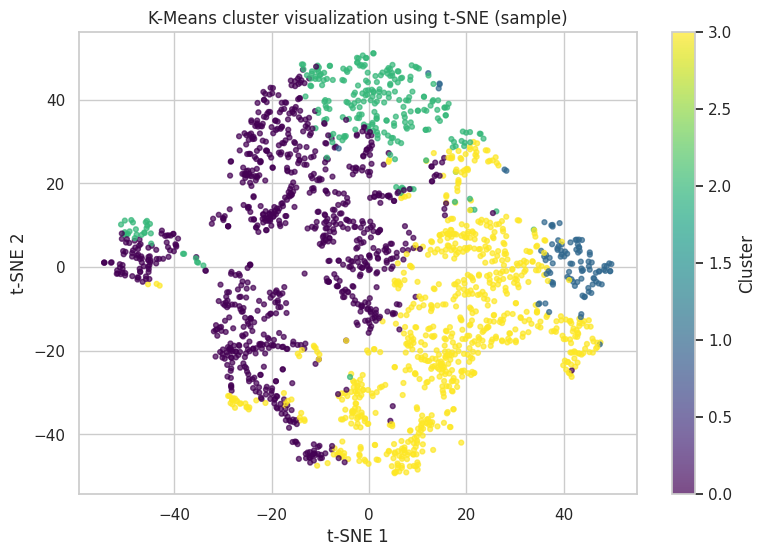

In [10]:
# t-SNE on a subset for manageable runtime. It is a visualization, not the clustering input.
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(X_scaled), size=min(2000, len(X_scaled)), replace=False)
X_tsne = TSNE(n_components=2, random_state=RANDOM_STATE, init="pca", learning_rate="auto", perplexity=30).fit_transform(X_scaled[idx])
plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels[idx], cmap="viridis", s=12, alpha=0.7)
plt.title("K-Means cluster visualization using t-SNE (sample)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.colorbar(scatter, label="Cluster")
plt.show()

## 9. Interpret the clusters

In [11]:
# Use unscaled values to make customer profiles easier to explain.
profile_data = df.drop(columns=["CUST_ID"], errors="ignore").copy()
profile_data["Cluster"] = kmeans_labels
profile_means = profile_data.groupby("Cluster").mean(numeric_only=True)
display(profile_means.round(2))

# Cluster sizes and representative feature means.
cluster_sizes = pd.Series(kmeans_labels).value_counts().sort_index().rename("customer_count")
display(cluster_sizes.to_frame())

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,1012.66,0.79,270.04,209.94,60.37,596.51,0.17,0.09,0.08,0.11,2.13,2.90,3278.71,974.26,569.00,0.08,11.45
1,3551.15,0.99,7681.62,5095.88,2587.21,653.64,0.95,0.74,0.79,0.07,2.09,89.36,9696.94,7288.74,1985.04,0.29,11.95
2,4602.45,0.97,501.86,320.19,181.76,4521.51,0.29,0.14,0.19,0.48,14.29,7.67,7546.16,3484.05,2020.80,0.03,11.39
3,894.91,0.93,1236.18,593.97,642.48,210.57,0.89,0.30,0.71,0.04,0.79,22.09,4213.21,1332.19,646.02,0.27,11.59


,customer_count
0,3977
1,409
2,1197
3,3367


## 10. Save outputs and write your interpretation

The CSV contains the original records plus the generated cluster assignment. Interpret cluster profiles from the actual output above; do not label a cluster as “high spenders” or similar unless the feature means support it.

In [12]:
output_path = Path("CC_GENERAL_kmeans_cluster_assignments.csv")
clustered.to_csv(output_path, index=False)
print(f"Saved cluster assignments to: {output_path.resolve()}")

Saved cluster assignments to: /mnt/data/Review-2-Final/Review-2/notebooks/CC_GENERAL_kmeans_cluster_assignments.csv


### Findings to complete after execution

- Selected number of clusters and why the elbow plot supports it:
- Silhouette / Davies–Bouldin / Calinski–Harabasz interpretation:
- What distinguishes each cluster based on profile means:
- Limitations (scaling, skew, arbitrary cluster IDs, and sampled t-SNE):